<p align="center">
  <span style="font-size:32px"><b>ISEL</b></span><br>
  <span style="font-size:26px"><b>Departamento de Engenharia Informática</b></span><br>
  <span style="font-size:24px"><b>Licenciatura em Engenharia Informática e Multimédia</b></span><br>
  <span style="font-size:22px"><b>Processamento de Imagem e Visão</b></span><br><br>
  <span style="font-size:20px"><b>Trabalho Prático 2</b></span><br>
  <span style="font-size:16px">Semestre de Inverno 2026/2027</span><br><br>
  <span style="font-size:16px">Docente: Prof. Pedro Jorge</span><br>
  <span style="font-size:16px">Data: Dezembro 2026</span><br><br>
  <span style="font-size:18px"><b>Trabalho realizado por:</b></span><br>
  <span style="font-size:16px">Beatriz Jesus nº52749</span><br>
  <span style="font-size:16px">Diana Oliveira nº52651</span><br>
</p>

<span style="font-size:19px"><b>Bibliotecas</b></span>

<span style="font-size:16px">Importações de Bibliotecas necessárias para a Implementação do Trabalho:<br></span>

<ul style="font-size:16px">
  <li><b>OpenCV</b> (<code>cv2</code>): Utilizada para processamento de imagens, visualização gráfica de sinais no domínio do tempo e análise visual.</li>
  <li><b>NumPy</b> (<code>numpy</code>): Utilizada para operações numéricas.</li>
  <li><b>Matplotlib</b> (<code>matplotlib.pyplot</code>): Utilizada para Visualização Grafica de Sinais no Domínio do Tempo e apoio à análise dos resultados.</li>

In [34]:

import cv2
import matplotlib.pyplot as plt
import numpy as np

A amostragem de frames deve ser espaçada por causa dos objetos, que entram e saiem. Em frames consecutivos, estes objetos apareceriam várias vezes e dominariam a mediana, podendo ser considerados como fundo. Para a mediana funcionar, cada pixel deve ver o fundo em mais de 50% das amostras.


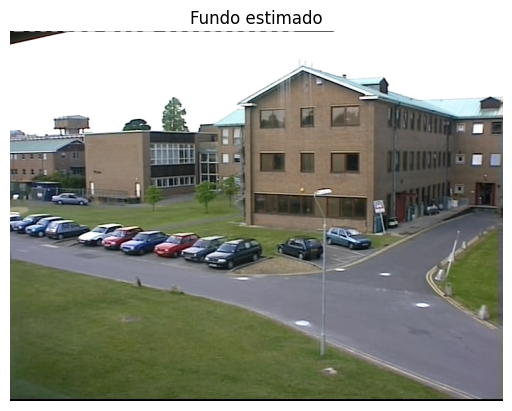

In [35]:
# 1. Estimação de imagem de fundo

def estimar_fundo(caminho_video, n_frames=50):
    video = cv2.VideoCapture(caminho_video)
    total = int(video.get(cv2.CAP_PROP_FRAME_COUNT)) #num total de frames
    # Escolhe n_frames (os seus índices) espaçados uniformemente ao longo do vídeo
    indices = np.linspace(0, total - 1, n_frames).astype(int)

    frames = []
    for i in indices:
        # vai buscar ao vídeo os frames cujos índices foram escolhidos, um de cada vez
        video.set(cv2.CAP_PROP_POS_FRAMES, i)
        # lê-se o frame correspondente à posição esoclhida a cima
        ok, frame = video.read()
        #Se estiver tudo bem, nao houver none, guarda na lista
        if ok:
            frames.append(frame)
    video.release() #fecha o video, ja nao se pode ler dele

    # Mediana ao longo do eixo temporal (axis=0), pixel a pixel
    return np.median(np.stack(frames, axis=0), axis=0).astype(np.uint8)


CAMINHO_VIDEO = "camera1.avi"
fundo = estimar_fundo(CAMINHO_VIDEO, n_frames=50)

cv2.imwrite("fundo.png", fundo)
fundo_rgb = cv2.cvtColor(fundo, cv2.COLOR_BGR2RGB)
plt.imshow(fundo_rgb)
plt.title("Fundo estimado")
plt.axis("off")
plt.show()

. Pos-se os frames a cinzento, porque a deteção de movimento só precisa de intensidade de luz, não de cor, e trabalhar com um único canal simplifica e acelera tudo. 

. É necessário atualizar o fundo, porque o fundo que se estimou no passo 1 é uma fotografia de um momento, e o mundo real muda ao longo do vídeo, por exemplo, a iluminação pode mudar, pode gaver sombras e reflexos que mudam, um carro pode sair do estacionamento, etc. Se o fundo ficar fixo, a imagem de referência vai ficando desatualizada e a subtração começa a dar falsos positivos.

. A máscara tem branco (255) onde há movimento. A dilatação engorda essas zonas brancas em ~7 píxeis para cada lado. Serve de margem de segurança: as bordas de uma pessoa ou carro costumam ser mal detetadas (a máscara fica um pouco mais pequena que o objeto real), e sem a margem esses píxeis de borda seriam atualizados no fundo, deixando um rasto fantasma.



Porquê o desfoque gaussiano no fundo e no frame?

Cada frame tem ruído (do sensor e da compressão do vídeo), por isso píxeis que deviam ser iguais ao fundo variam uns valores para cima ou para baixo. Sem desfoque, alguns desses píxeis ultrapassam o LIMIAR e aparecem na máscara como pontos brancos soltos, que não são movimento. O desfoque faz a média de cada píxel com os vizinhos e atenua esse ruído (slides 6 e 7 do capítulo 5).

Os dois têm de ter o mesmo tratamento. O fundo vem de uma mediana de muitos frames, que sai mais limpa do que um frame isolado. Se só um deles fosse desfocado, a diferença apanhava também a diferença de nitidez entre ambos, e não só o movimento.

Se o desfoque for demasiado forte, os contornos dos objetos ficam menos definidos. 

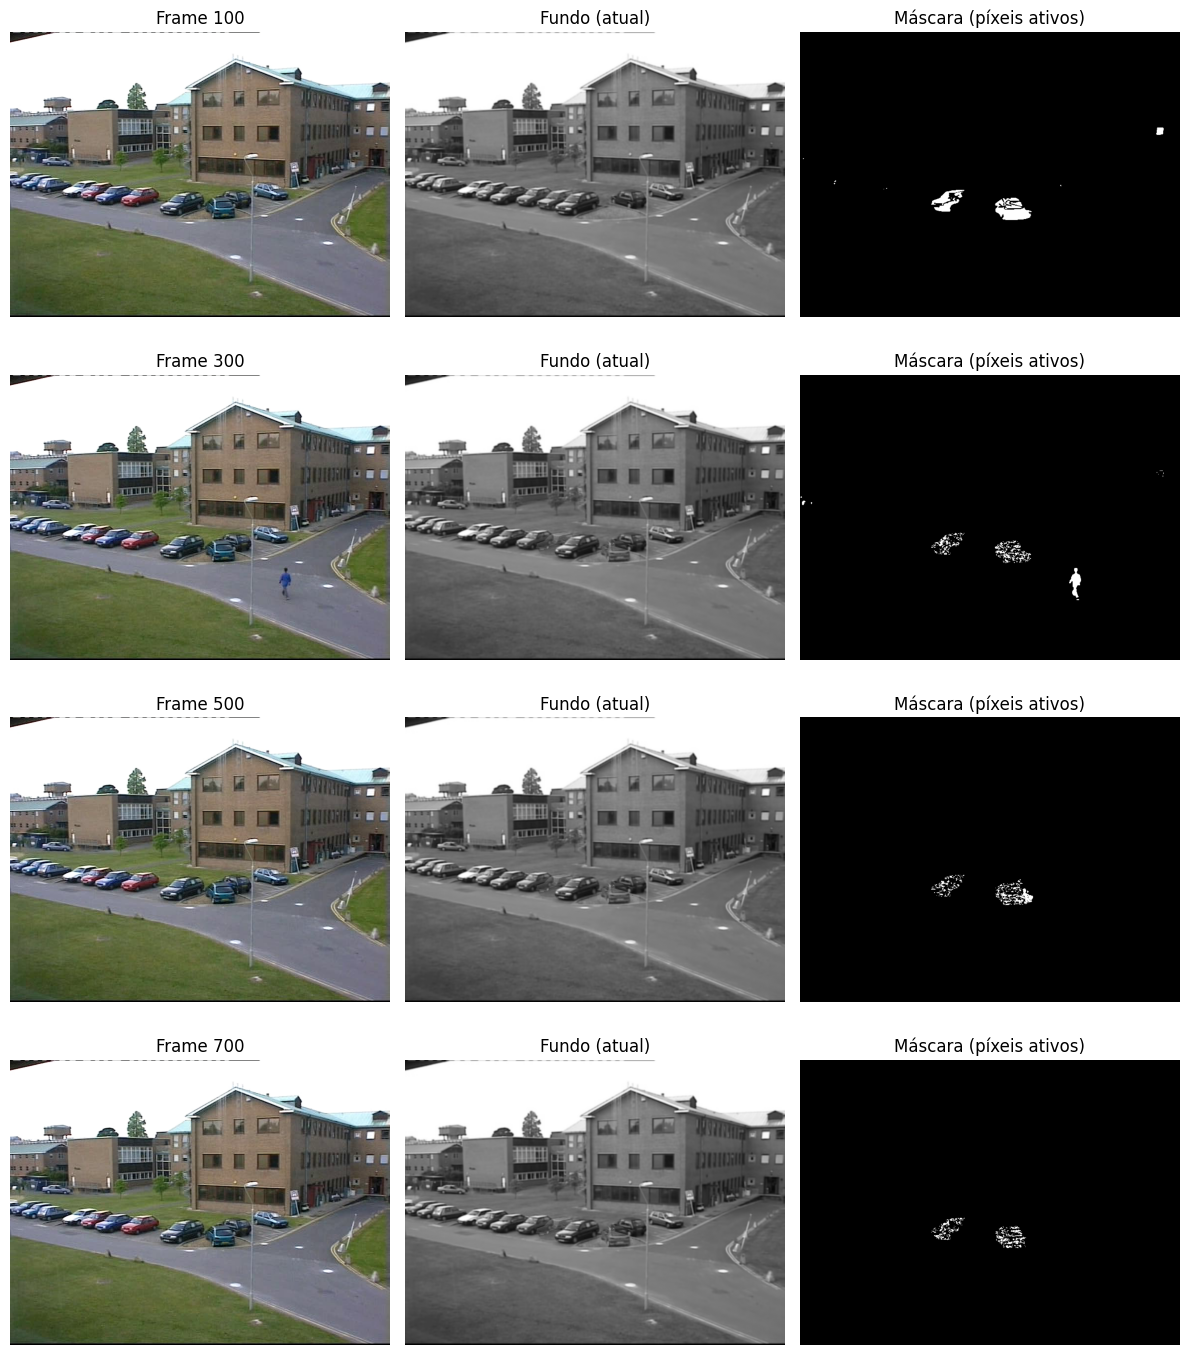

In [ ]:
# 2. Deteção de píxeis ativos através da binarização e atualização do fundo

def detetar_pixeis_ativos(gray, fundo_g, limiar=30):
    """Devolve a máscara binária dos píxeis diferentes do fundo."""
    fundo_u8 = fundo_g.astype(np.uint8)  #passou-se para int8 porque abdsdiff precisa de ter o mesmo tipo de dados e gray está a int 8 
    diff = cv2.absdiff(gray, fundo_u8)    # |frame - fundo|
    _, mascara = cv2.threshold(diff, limiar, 255, cv2.THRESH_BINARY) #binarização, limiarização
    return mascara



def atualizar_fundo(fundo_g, gray, mascara,contador, alpha=0.99, n_parado=100, alpha_parado=0.95 ):
    """Atualiza o fundo só nos píxeis SEM movimento: fundo = α·fundo + (1-α)·frame."""

    # contador de frames consecutivos ativos, por píxel
    contador[mascara > 0] += 1
    contador[mascara == 0] = 0

    #Atualização normal
    # Dilatar a máscara para proteger também as bordas dos objetos
    mascara_larga = cv2.dilate(mascara, np.ones((15, 15), np.uint8))
    #inverter a máscara, para o fundo ficar a branco, pois é o que queremos atualiar
    so_fundo = cv2.bitwise_not(mascara_larga)
    #atualiza o fundo, misturando uma pequena parte do frame atual nele, mas só nos píxeis onde so_fundo é branco.
    #o alpha do open cv pesa o frame novo, por isso, passa-se 1-alpha, pois alpha=0.99 é do fundo. 
    cv2.accumulateWeighted(gray, fundo_g, 1-alpha, mask=so_fundo)


    # Se houver píxeis parados há muito tempo (ha mais de 100 frames) serão considerados pelo fundo
    parados = ((contador > n_parado) * 255).astype(np.uint8)
    cv2.accumulateWeighted(gray, fundo_g, 1 - alpha_parado, mask=parados)
    # O contador guarda, para cada píxel, há quantos frames seguidos está ativo (a branco na máscara). Quando um píxel passa de 100 frames seguidos, 
    # começa a ser atualizado no fundo com alpha_parado. Um carro parado tem muitos píxeis nessa situação, por isso, na prática, o carro inteiro acaba por ser absorvido. Mas cada píxel é avaliado por si.



LIMIAR = 30
ALPHA = 0.99 
video = cv2.VideoCapture(CAMINHO_VIDEO)
total = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

# fundo em cinzentos + desfoque, em float32 (obrigatório para o accumulateWeighted)
fundo_gray = cv2.cvtColor(fundo, cv2.COLOR_BGR2GRAY)
fundo_g = cv2.GaussianBlur(fundo_gray, (5, 5), 0).astype(np.float32)
contador = np.zeros(fundo_g.shape, dtype=np.int32) #contador de frames em que cada pixel esta ativo

frames_a_mostrar = [100, 300, 500, 700]
resultados = []


n = 0
while True:
    ok, frame = video.read()
    if not ok:
        break

    # o frame tem de passar a cinzentos e ser desfocado, tal como o fundo
    gray = cv2.GaussianBlur(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (5, 5), 0)

    #objetos com moviento ficam a branco e o fundo a preto
    mascara = detetar_pixeis_ativos(gray, fundo_g, LIMIAR)
    
    atualizar_fundo(fundo_g, gray, mascara, contador, ALPHA)

    if n in frames_a_mostrar:
        resultados.append((n, frame.copy(), fundo_g.astype(np.uint8), mascara))
    n += 1
video.release()


#para mostrar
fig, eixos = plt.subplots(len(resultados), 3, figsize=(12, 3.5 * len(resultados)))
for linha, (n, frame, fundo_atual, mascara) in zip(np.atleast_2d(eixos), resultados):
    linha[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)); linha[0].set_title(f"Frame {n}")
    linha[1].imshow(fundo_atual, cmap="gray");               linha[1].set_title("Fundo (atual)")
    linha[2].imshow(mascara, cmap="gray");                   linha[2].set_title("Máscara (píxeis ativos)")
    for ax in linha:
        ax.axis("off")
plt.tight_layout()
plt.show()






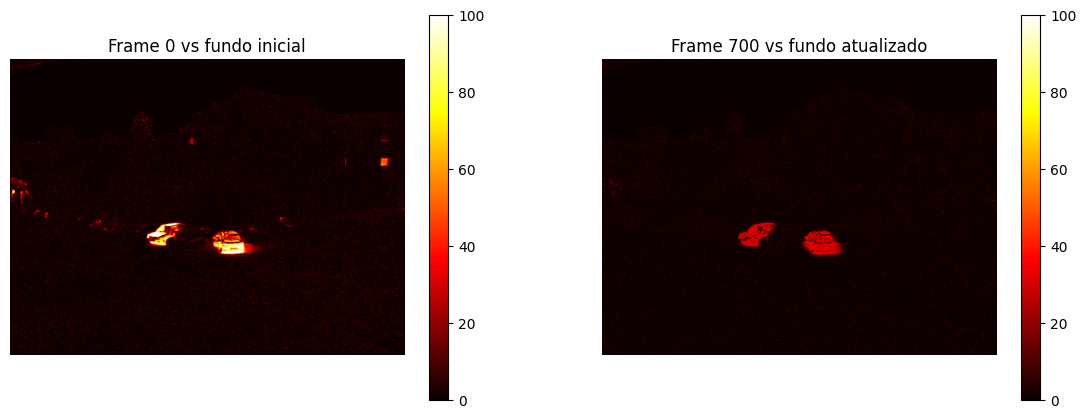

In [ ]:
# SÓ PARA ENTENDER O PROBLEMA:
# Diagnóstico: quão diferente é cada píxel do fundo? (mapa de calor)
video = cv2.VideoCapture(CAMINHO_VIDEO)
ok, f0 = video.read()
video.release()

g0 = cv2.GaussianBlur(cv2.cvtColor(f0, cv2.COLOR_BGR2GRAY), (5, 5), 0)
fundo_inicial = cv2.GaussianBlur(cv2.cvtColor(fundo, cv2.COLOR_BGR2GRAY), (5, 5), 0)

n_ult, frame_ult, fundo_ult, _ = resultados[-1]
g_ult = cv2.GaussianBlur(cv2.cvtColor(frame_ult, cv2.COLOR_BGR2GRAY), (5, 5), 0)

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for ax, img, titulo in zip(eixos,
        [cv2.absdiff(g0, fundo_inicial), cv2.absdiff(g_ult, fundo_ult)],
        ["Frame 0 vs fundo inicial", f"Frame {n_ult} vs fundo atualizado"]):
    im = ax.imshow(img, cmap="hot", vmin=0, vmax=100)
    ax.set_title(titulo); ax.axis("off")
    plt.colorbar(im, ax=ax)
plt.show()

In [38]:
# 3. Utilização de operadores morfológicos para remover ruído e preencher falhas

def limpar_mascara(mascara, area_min=150, k_abertura=3, k_fecho=9):
    # 1. Abertura (erosão + dilatação): elimina pontos brancos pequenos e isolados
    e_abertura = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_abertura, k_abertura))
    abertura = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, e_abertura)

    # 2. Fecho (dilatação + erosão): preenche buracos e liga partes do mesmo objeto
    e_fecho = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_fecho, k_fecho))
    fecho = cv2.morphologyEx(abertura, cv2.MORPH_CLOSE, e_fecho)

    # # 3. Remover componentes ligadas com área pequena (ruído que sobreviveu)
    # n, labels, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    # limpa = np.zeros_like(m)
    # for i in range(1, n):                       # 0 é o fundo
    #     if stats[i, cv2.CC_STAT_AREA] >= area_min:
    #         limpa[labels == i] = 255
    # return limpa


pq priemiro a abertura??


Object `abertura` not found.
